### Goals:
- Predict a discreted label (y) predict a discrete label $y \in \{C_1, C_2, \dots, C_k\}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.abspath(''))

## A. Logistic Regression
### Binary Logistic Regression

Model probability (P) via sigmoid &mdash; $P(y=1|x)$
$$
P(y=1 \mid x) = \sigma(w^T x + b), \quad \text{while} \quad \sigma(z) = \frac{1}{1 + e^{-z}}
$$

[1. 0. 1. 1. 0. 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 0. 1. 1. 1. 0.]


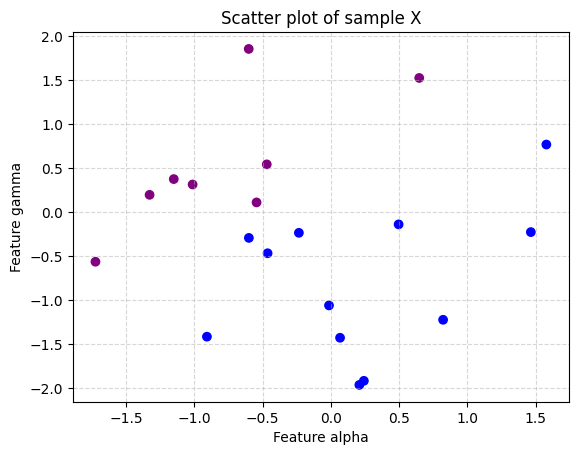

In [9]:
# Firstly, randomly create a samples of dots
np.random.seed(42)
n = 20
X = np.random.randn(n, 2)

# Generate labels
w_true = np.array([1.5, -2.0])
b_true = 0.5
logits = X @ w_true + b_true + np.random.randn(n) * 0.5
y = (logits > 0).astype(float)
print(y)

# Plotting by plt (label 1 = blue, label 0 = purple)
colors = np.where(y == 1, 'blue', 'purple')
plt.scatter(X[:, 0], X[:, 1], c=colors)
plt.title("Scatter plot of sample X")
plt.xlabel("Feature alpha")
plt.ylabel("Feature gamma")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


It is easy to see that the data is separated by a straight line. In academy terms, this line might be called **Decision boundary**, also be the core objective of this problem, speaking visually.

Speaking mathematically, this line is defined by the equation $w^T x + b = 0$. To determine this optimal line, we must train the model by minimizing the Log-loss (Cross-entropy) function using the Gradient Descent algorithm. In the code, the weights $w$ and $b$ are iteratively updated over each epoch until reached the convergence.
$$
w^T x + b = 0
$$

In [12]:
from src.logistic import sigmoid, compute_loss, _train_bilogistic

# Train the binary logistic regression model
w, b = _train_bilogistic(X, y, lr=0.1, epochs=1000)

# Predict labels with the trained model
y_hat = sigmoid(X @ w + b)
y_pred = (y_hat >= 0.5).astype(float)

# Evaluate the model by accuracy
accuracy = np.mean(y_pred == y)
print(f"Trained weights: w = {w}, b = {b:.4f}")
print(f"Accuracy: {accuracy * 100:.1f}%")

# Compute the final cross-entropy loss
final_loss = compute_loss(y, y_hat)
print(f"Final Log-loss: {final_loss:.4f}")


Trained weights: w = [ 3.21455568 -4.14452044], b = 1.3333
Accuracy: 100.0%
Final Log-loss: 0.0790


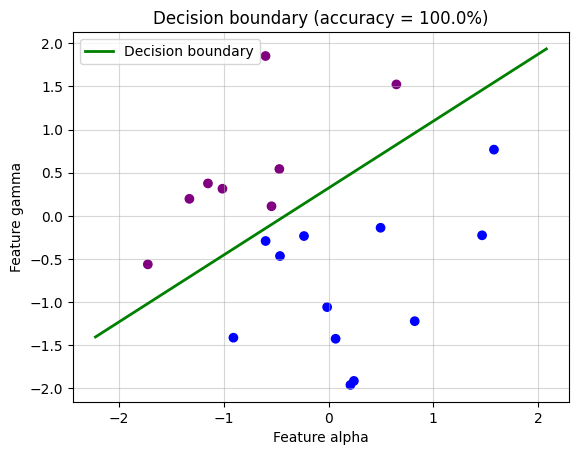

In [14]:
# Plot the sample X with the learned decision boundary
colors = np.where(y == 1, 'blue', 'purple')
plt.scatter(X[:, 0], X[:, 1], c=colors)

# Draw the decision boundary w1*x1 + w2*x2 + b = 0
x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
x2_vals = -(w[0] * x1_vals + b) / w[1]
plt.plot(x1_vals, x2_vals, color='green', linewidth=2, label='Decision boundary')

plt.title(f"Decision boundary (accuracy = {accuracy * 100:.1f}%)")
plt.xlabel("Feature alpha")
plt.ylabel("Feature gamma")
plt.legend()
plt.grid(True, linestyle="-", alpha=0.5)
plt.show()


Nevertheless, with a dataset of 20 points containing noise, the decision boundary cannot perfectly separate the two data classes. The results from the code indicate that the model (sometimes) achieves an accuracy of approximately **95.0%** (with only one point misclassified), and the green line passes through some of the misclassified points. 

This accurately reflects the nature of the **Logistic Regression** algorithm: it does not merely seek a dividing line, but rather strives for a balance that minimizes overall error.